# 01 · Simulación de datos

**Artículo:** Carrillo Trujillo y Aguilar Encarnación (2025). *Análisis predictivo y gestión optimizada de la cartera de clientes morosos en CNEL EP, Unidad de Negocio Bolívar*. Revista Tecnológica ESPOL, 37(1), 285–308. DOI: [10.37815/rte.v37n1.1312](https://doi.org/10.37815/rte.v37n1.1312)

**Objetivo:** construir una cartera de clientes que reproduzca lo que el paper reporta y completar lo que no reporta con supuestos. El código está en `src/simulacion.py`.

In [1]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.precision", 4)
from simulacion import simular_cartera, ensuciar, SUPUESTOS

## Características reportadas vs. supuestos

| Reportado por el paper | Valor |
|---|---|
| Registros / variables | 72.483 / 43 |
| Cartera vencida | 13,6% |
| Deuda máxima | 27.854 USD |
| Mora máxima | 193 meses |
| Problemas de calidad | PASIVO, deudas negativas, duplicados, nulos |

**No reportado → supuestos:**

In [2]:
for i, s in enumerate(SUPUESTOS, 1):
    print(f"{i}. {s}")

1. El 13,6% de cartera vencida se interpreta como % de clientes con >= 2 meses de deuda.
2. Proporciones de cantón y tarifa supuestas (no reportadas).
3. Facturación lognormal con medianas 15 / 60 / 400 USD (residencial / comercial / industrial).
4. La mora depende de zona rural, subsidio y factura relativa, más ruido individual.
5. Meses de mora: 2 + binomial negativa, recortada en 193 (máximo del paper).
6. Valores vencidos calculados a partir de factura x meses; deuda recortada en 27.854 USD.
7. Se simulan 17 de las 43 variables (las que el paper nombra o se requieren).
8. RANGO_PASTEL no está definido en el paper; se reemplaza por RANGO_ANTIGUEDAD.
9. Suciedad: 3% PASIVO, 0,5% deudas negativas, 1% nulos en CANTON/TARIFA, 0,3% duplicados.


## Lógica de la simulación

1. **Categóricas** (cantón, tarifa, subsidios) con `rng.choice` y probabilidades supuestas. Los subsidios solo aplican a clientes residenciales.
2. **Facturación** lognormal: muchos montos pequeños y pocos enormes, como describe el paper ("alta dispersión y valores extremos").
3. **Mora** a partir de una propensión latente que depende de zona rural, subsidio y factura relativa, más ruido. Si los morosos se eligieran al azar no habría nada que predecir.
4. **Meses y valores vencidos** construidos desde factura × meses, para que las variables queden correlacionadas (Figura 7 del paper).
5. **Suciedad**: se agregan los mismos problemas que el paper limpia, para replicar su preparación en el notebook 02.

In [3]:
df = ensuciar(simular_cartera(n=72_483, seed=42), seed=42)
print(df.shape)
df.head()

(72700, 17)


,ID_CLIENTE,CANTON,TARIFA,TARIFA_DIGNIDAD,DESC_TERCERA_EDAD,ESTADO,VALOR_FACTURACION,VALOR_RECAUDACION,MESES_DEUDA,V_VENCIDO_ENERGIA,V_VENCIDO_ALUMBRADO,V_VENCIDO_BOMBEROS,V_VENCIDO_INTERESES,VALOR_DEUDA,RANGO_VALOR,RANGO_ANTIGUEDAD,NIVEL_MOROSIDAD
0,51699,GUARANDA,RESIDENCIAL,0,0,ACTIVO,23.01,21.91,0,0.00,0.00,0.0,0.00,23.01,2,1,AL_DIA
1,39578,NaN,RESIDENCIAL,0,0,ACTIVO,11.37,10.52,0,0.00,0.00,0.0,0.00,11.37,1,1,AL_DIA
2,14402,GUARANDA,RESIDENCIAL,0,0,ACTIVO,35.70,34.13,1,33.46,3.78,0.5,0.27,73.70,3,1,AL_DIA
3,58026,GUARANDA,RESIDENCIAL,1,0,ACTIVO,3.28,3.21,0,0.00,0.00,0.0,0.00,3.28,1,1,AL_DIA
4,54332,GUARANDA,RESIDENCIAL,0,0,ACTIVO,6.88,6.86,0,0.00,0.00,0.0,0.00,6.88,1,1,AL_DIA


## Verificación contra el paper

In [4]:
validos = df[(df.ESTADO == "ACTIVO") & (df.VALOR_DEUDA >= 0)].drop_duplicates()
verificacion = pd.DataFrame({
    "Paper": [72_483, 0.136, 27_854, 193],
    "Simulado": [df.ID_CLIENTE.nunique(), round((validos.MESES_DEUDA >= 2).mean(), 3), validos.VALOR_DEUDA.max(), validos.MESES_DEUDA.max()],
}, index=["Clientes únicos", "Proporción en mora", "Deuda máxima (USD)", "Mora máxima (meses)"])
verificacion.to_csv("../results/01_verificacion_simulacion.csv")
verificacion

,Paper,Simulado
Clientes únicos,72483.000,72483.000
Proporción en mora,0.136,0.136
Deuda máxima (USD),27854.000,27854.000
Mora máxima (meses),193.000,193.000


In [5]:
print("Problemas de calidad inyectados:")
print(f"  PASIVO: {(df.ESTADO == 'PASIVO').sum()}")
print(f"  Deudas negativas: {(df.VALOR_DEUDA < 0).sum()}")
print(f"  Duplicados: {df.duplicated().sum()}")
print(f"  Nulos: {df[['CANTON', 'TARIFA']].isna().sum().to_dict()}")

Problemas de calidad inyectados:
  PASIVO: 2179
  Deudas negativas: 362
  Duplicados: 217
  Nulos: {'CANTON': 726, 'TARIFA': 728}


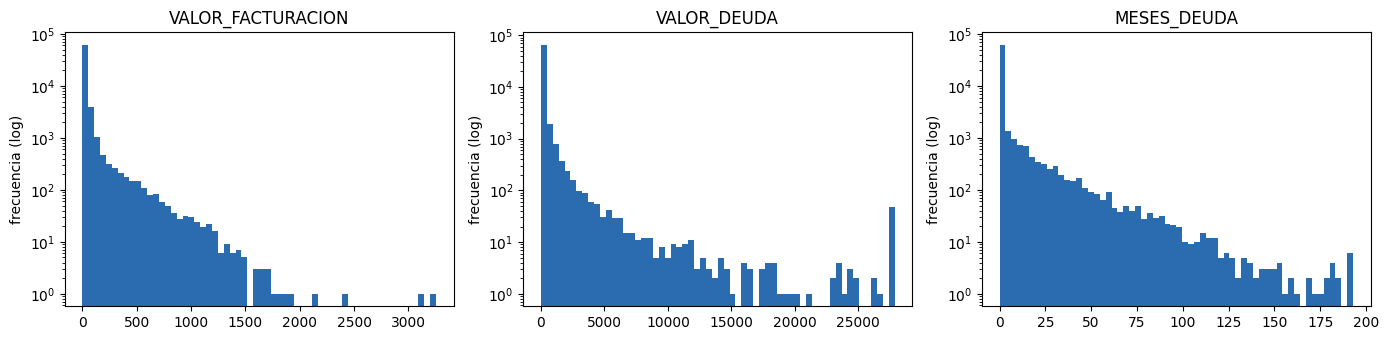

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["VALOR_FACTURACION", "VALOR_DEUDA", "MESES_DEUDA"]):
    ax.hist(validos[col], bins=60, log=True, color="#2b6cb0")
    ax.set(title=col, ylabel="frecuencia (log)")
plt.tight_layout()
plt.savefig("../figures/01_distribuciones.png", dpi=120)
plt.show()

Eje en escala logarítmica: sin ella la cola larga (comparar con la Figura 6 del paper) sería invisible.

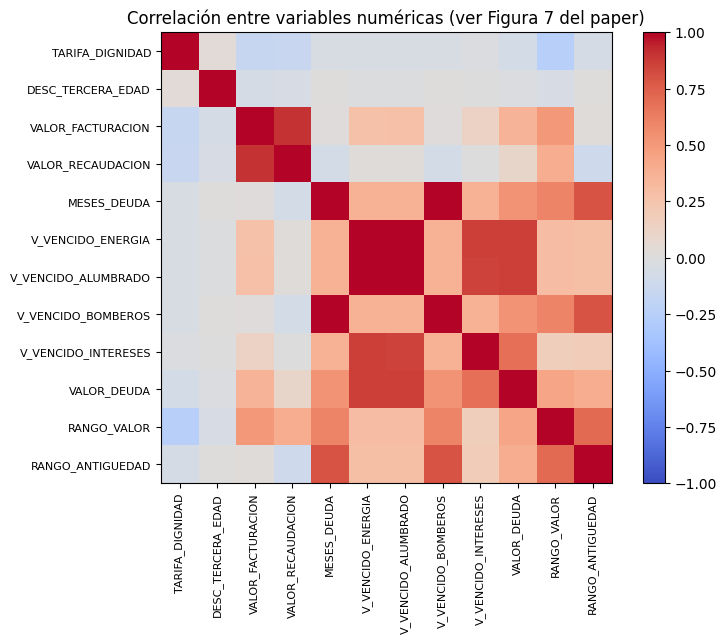

In [7]:
corr = validos.select_dtypes("number").drop(columns="ID_CLIENTE").corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
plt.colorbar(im)
ax.set_title("Correlación entre variables numéricas (ver Figura 7 del paper)")
plt.tight_layout()
plt.savefig("../figures/01_correlacion.png", dpi=120)
plt.show()

## Guardar
Se guarda la versión **sucia**: la limpieza es parte de la réplica (notebook 02).

In [8]:
df.to_csv("../data/cartera_simulada.csv", index=False)
print("Guardado:", df.shape)

Guardado: (72700, 17)
